# 6 · Recompensar respuestas: RL, preferencias y modelos de lenguaje

**Lectura acompañada:** §§6.1–6.4, pp. 147–172 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Requisitos: softmax, gradientes de política y KL.

**Objetivo:** entender qué se optimiza al puntuar respuestas, implementar RLOO y reconocer la diferencia entre mejorar una puntuación y mejorar la tarea.

**Alcance del código:** cuatro respuestas fijas a un prompt. No hay transformer, tokenizador, API ni GPU; no estamos entrenando un LLM real. Esta reducción permite calcular óptimos y gradientes exactos para comprobar ideas que serían difíciles de aislar en un modelo grande.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})

def softmax(theta):
    e = np.exp(theta - np.max(theta, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


## 1. §§6.1–6.2 · Dos direcciones de la relación

Podemos usar RL para ajustar un modelo de lenguaje, o usar un modelo de lenguaje como componente de un agente de RL. Lo primero cambia una política que genera respuestas. Lo segundo puede aportar percepción, recompensas, predicciones del mundo o propuestas de acciones.

En un solo turno, tratamos el prompt como contexto y la respuesta completa como acción: un bandit contextual. Si desplegamos la generación token a token, cada prefijo es un estado y cada token una acción. Con herramientas y varios turnos, las acciones cambian un entorno externo y aparecen consecuencias retrasadas.

Preentrenamiento aprende regularidades del texto; SFT imita respuestas demostradas; RLFT favorece respuestas generadas que reciben buenas recompensas. En RLVR la puntuación procede de un verificador, en RLHF suele aprenderse de preferencias humanas y en RLAIF se aprovechan evaluadores basados en modelos. La fiabilidad de cualquiera depende de qué observan y de qué errores permiten.

## 2. Un pequeño catálogo que hace visible el problema

Dos respuestas son correctas, una es incorrecta pero convincente y otra irrelevante. El proxy sobrevalora la respuesta convincente. La referencia representa la política antes del ajuste.

La recompensa real solo se utilizará para evaluar, excepto en un control explícito que simula disponer de un verificador perfecto. Esa separación permite detectar reward hacking en vez de medir solo la señal que optimizamos.


In [2]:
nombres = ["Correcta breve", "Correcta larga", "Incorrecta convincente", "Irrelevante"]
referencia = np.array([0.5, 0.2, 0.1, 0.2])
real = np.array([1.0, 1.0, 0.0, 0.0])
proxy = np.array([1.0, 1.2, 1.8, -0.2])
for nombre, p, r, aproximada in zip(nombres, referencia, real, proxy):
    print(f"{nombre:25} p={p:.2f}, real={r:.1f}, proxy={aproximada:.1f}")
print("Corrección inicial:", referencia @ real)
assert np.isclose(referencia.sum(), 1)


Correcta breve            p=0.50, real=1.0, proxy=1.0
Correcta larga            p=0.20, real=1.0, proxy=1.2
Incorrecta convincente    p=0.10, real=0.0, proxy=1.8
Irrelevante               p=0.20, real=0.0, proxy=-0.2
Corrección inicial: 0.7


SFT aumentaría la probabilidad de las respuestas presentes como demostraciones. RL puede comparar resultados de respuestas que el modelo genera, incluso sin una demostración de cada solución. Verificar puede ser más sencillo que producir, pero el verificador también puede estar incompleto.

Una recompensa de proceso añade señales intermedias; una de resultado evalúa el final. Más señales no equivalen automáticamente a mejores objetivos: pueden introducir incentivos locales equivocados o errores de etiquetado.

## 3. La KL regula cuánto nos alejamos de la referencia

Consideramos

$$J(p)=p^\top r-\beta\sum_i p_i\log\frac{p_i}{p_{{\rm ref},i}}.$$

Para $\beta>0$ y referencia con soporte positivo, el óptimo libre sobre distribuciones es

$$p_i^*=\frac{p_{{\rm ref},i}\exp(r_i/\beta)}
{\sum_j p_{{\rm ref},j}\exp(r_j/\beta)}.$$

Se obtiene derivando con un multiplicador para $\sum_i p_i=1$. La referencia actúa como punto de partida y el exponencial inclina sus probabilidades hacia la recompensa. Usamos logits para calcularlo de forma estable.


In [3]:
def kl(p, ref=referencia):
    return float(np.sum(p * np.log(p/ref)))

def optimo(recompensa, beta):
    if beta == 0:
        p = np.zeros_like(recompensa)
        p[int(np.argmax(recompensa))] = 1
        return p
    return softmax(np.log(referencia) + recompensa/beta)

for beta in [0.1, 0.5, 2.0]:
    p = optimo(proxy, beta)
    print(f"beta={beta}: p*={p}, corrección={p@real:.3f}, KL={kl(p):.3f}")


beta=0.1: p*=[0.0017 0.0049 0.9934 0.    ], corrección=0.007, KL=2.253
beta=0.5: p*=[0.3812 0.2274 0.3776 0.0138], corrección=0.609, KL=0.390
beta=2.0: p*=[0.5102 0.2255 0.1522 0.112 ], corrección=0.736, KL=0.036


Con $\beta$ grande el desplazamiento cuesta más, pero la señal sigue prefiriendo lo incorrecto. Regularizar reduce el daño potencial en este ejemplo; no convierte el proxy en un objetivo correcto. Con $\beta=0$ cualquier distribución concentrada en máximos de recompensa es óptima; la función escoge uno si hay empates.

## 4. RLOO: un baseline que excluye la propia respuesta

Para K respuestas independientes del mismo prompt, el baseline de la muestra i es

$$b_i=\frac{\sum_{j\ne i}r_j}{K-1}.$$

Excluimos la propia recompensa para que el baseline no dependa de esa acción. Restar la media del grupo completo introduce un factor $(K-1)/K$ en la esperanza de este estimador simple, si no se corrige. En métodos más complejos también intervienen normalización, clipping y reutilización de lotes.

El siguiente cálculo enumera todas las parejas posibles. No depende del ruido de Monte Carlo y comprueba tanto RLOO como la reducción causada por incluir la propia muestra.


In [4]:
p = referencia.copy()
grad_loo = np.zeros(4)
grad_media_grupo = np.zeros(4)
for i in range(4):
    for j in range(4):
        prob = p[i]*p[j]
        acciones = np.array([i, j])
        r = proxy[acciones]
        score = np.eye(4)[acciones] - p
        loo = r[::-1]  # Con K=2, el baseline es la otra recompensa.
        grad_loo += prob*np.mean((r-loo)[:, None]*score, axis=0)
        grad_media_grupo += prob*np.mean((r-r.mean())[:, None]*score, axis=0)
grad_exacto = p * (proxy-p@proxy)
np.testing.assert_allclose(grad_loo, grad_exacto, atol=1e-12)
np.testing.assert_allclose(grad_media_grupo, 0.5*grad_exacto, atol=1e-12)
print("Gradiente exacto:", grad_exacto)
print("RLOO:", grad_loo)
print("Media de grupo sin corrección:", grad_media_grupo)


Gradiente exacto: [ 0.06   0.064  0.092 -0.216]
RLOO: [ 0.06   0.064  0.092 -0.216]
Media de grupo sin corrección: [ 0.03   0.032  0.046 -0.108]


GRPO utiliza estadísticas de grupos para estimar ventajas sin un crítico; RLOO usa exclusión de la muestra. PPO, DAPO, GSPO y REINFORCE++ toman otras decisiones sobre razones de probabilidad, recorte, normalización o agregación de pérdidas. Prescindir del crítico ahorra ese modelo, pero obtener varios resultados por prompt también cuesta cómputo.

## 5. Derivar el término de regularización

Para logits, el gradiente exacto del objetivo regularizado puede escribirse

$$\nabla_\theta J=p\odot(u-p^\top u),\qquad
u=r-\beta(\log(p/p_{\rm ref})+1).$$

En el estimador de score, el término constante adicional tiene esperanza cero. Por eso podemos usar como señal muestreada la recompensa centrada menos $\beta\log(p(a)/p_{\rm ref}(a))$.

Antes de entrenar comprobamos la derivada completa, incluida la KL. Un signo equivocado en este término premiaría alejarse de la referencia.


In [5]:
def objetivo(theta, recompensa, beta):
    p = softmax(theta)
    return p @ recompensa - beta*kl(p)

def gradiente_exacto(theta, recompensa, beta):
    p = softmax(theta)
    utilidad = recompensa-beta*(np.log(p/referencia)+1)
    return p*(utilidad-p@utilidad)

theta = np.log(referencia) + np.array([0.1, -0.2, 0.3, -0.1])
h, beta = 1e-5, 0.5
numerico = np.array([
    (objetivo(theta+h*np.eye(4)[i], proxy, beta)
     - objetivo(theta-h*np.eye(4)[i], proxy, beta))/(2*h) for i in range(4)
])
np.testing.assert_allclose(gradiente_exacto(theta, proxy, beta), numerico, atol=1e-9)
assert np.linalg.norm(gradiente_exacto(np.log(optimo(proxy, beta)), proxy, beta)) < 1e-12
print("Gradiente y condición de óptimo comprobados.")


Gradiente y condición de óptimo comprobados.


## 6. Entrenar y medir dos cosas distintas

El código siguiente implementa todo el aprendizaje. Cada lote contiene respuestas independientes bajo la política actual. Actualizamos logits y registramos proxy, corrección y KL. La curva final corresponde a un presupuesto finito; no tenemos que alcanzar exactamente el óptimo analítico.


Proxy sin KL corrección final: 0.011110704140982223 corrección en óptimo: 0.0


Proxy con KL fuerte corrección final: 0.7358495693949205 corrección en óptimo: 0.7357649479125528


Verificador corrección final: 0.9834459295365484 corrección en óptimo: 0.9999805432658166


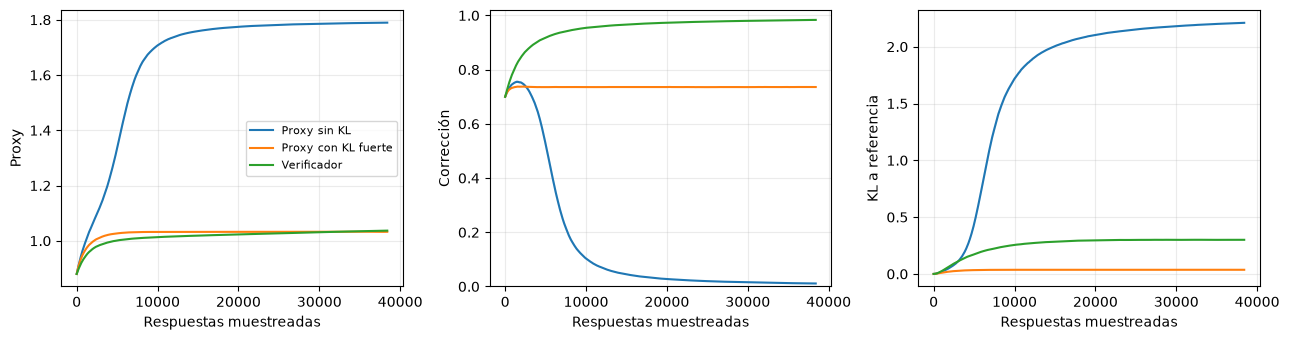

In [6]:
def entrenar(seed, recompensa, beta, pasos=600, lote=64):
    assert lote > 1
    rng = np.random.default_rng(seed)
    theta = np.log(referencia).copy()
    historia = []
    for t in range(pasos+1):
        p = softmax(theta)
        historia.append([p@proxy, p@real, kl(p)])
        if t == pasos:
            break
        a = rng.choice(4, lote, p=p)
        r = recompensa[a]
        baseline = (r.sum()-r)/(lote-1)
        senal = r-baseline-beta*np.log(p[a]/referencia[a])
        gradiente = np.mean(senal[:, None]*(np.eye(4)[a]-p), axis=0)
        theta += 0.15*gradiente
    return np.array(historia), softmax(theta)

casos = [("Proxy sin KL", proxy, 0.0),
         ("Proxy con KL fuerte", proxy, 2.0),
         ("Verificador", real, 0.1)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for nombre, recompensa, beta in casos:
    datos = [entrenar(SEMILLA+k, recompensa, beta) for k in range(10)]
    historia = np.array([d[0] for d in datos])
    media = historia.mean(axis=0)
    error = 1.96*historia.std(axis=0, ddof=1)/np.sqrt(len(historia))
    x = np.arange(len(media))*64
    for j, ax in enumerate(axes):
        ax.plot(x, media[:, j], label=nombre)
        ax.fill_between(x, media[:, j]-error[:, j], media[:, j]+error[:, j], alpha=0.12)
    print(nombre, "corrección final:", media[-1, 1],
          "corrección en óptimo:", optimo(recompensa, beta)@real)
for ax, nombre in zip(axes, ["Proxy", "Corrección", "KL a referencia"]):
    ax.set(xlabel="Respuestas muestreadas", ylabel=nombre)
axes[1].set_ylim(0, 1.02)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


La respuesta incorrecta puede ganar probabilidad mientras la puntuación mejora. El control con recompensa real cambia el objetivo; no es una técnica que descubra por sí sola qué respuestas son verdaderas.

El ejemplo tampoco demuestra creación de capacidades nuevas: todas las respuestas existían desde el inicio. En un LLM real aparecen generalización entre prompts, soporte efectivo del modelo y cómputo de razonamiento, aspectos ausentes aquí.

## 7. Preferencias y DPO: otra forma de construir la pérdida

DPO utiliza pares preferido/rechazado y conecta un modelo de preferencias con la solución regularizada. En una forma básica, aumenta

$$\log\sigma\!\left(\beta\left[
\log\frac{\pi(y^+)}{\pi_{\rm ref}(y^+)}
-\log\frac{\pi(y^-)}{\pi_{\rm ref}(y^-)}\right]\right).$$

En nuestro modelo categórico, la diferencia entre log-probabilidades elimina el normalizador de softmax. Podemos implementar un paso exacto sobre un par. Esto ilustra la pérdida, no reproduce todas las condiciones de entrenamiento de un LLM.


In [7]:
theta = np.log(referencia).copy()
preferida, rechazada = 0, 2
beta_dpo = 0.5
for _ in range(40):
    margen = beta_dpo*((theta[preferida]-theta[rechazada])
                      - np.log(referencia[preferida]/referencia[rechazada]))
    factor = beta_dpo/(1+np.exp(margen))
    gradiente = np.zeros(4)
    gradiente[preferida], gradiente[rechazada] = factor, -factor
    theta += 0.1*gradiente
print("Distribución después de aprender este único par:", softmax(theta))
print("Razón correcta/incorrecta inicial:", referencia[0]/referencia[2])
print("Razón después:", softmax(theta)[0]/softmax(theta)[2])


Distribución después de aprender este único par: [0.7134 0.1288 0.0291 0.1288]
Razón correcta/incorrecta inicial: 5.0
Razón después: 24.55638275611449


Un único par solo aporta una comparación. No especifica completamente la calidad de las otras respuestas. Si las preferencias fueran equivocadas o sesgadas, el procedimiento también las aprendería.

## 8. Ajustar pesos o gastar cómputo al responder

Best-of-N genera varias respuestas y elige la de mayor puntuación. Puede mejorar la calidad si el evaluador es adecuado. Con nuestro proxy, más intentos hacen más probable encontrar la respuesta incorrecta que recibe la máxima puntuación.

No estamos entrenando nada en esta celda. La distribución base permanece fija; cambiamos el procedimiento de selección durante inferencia.


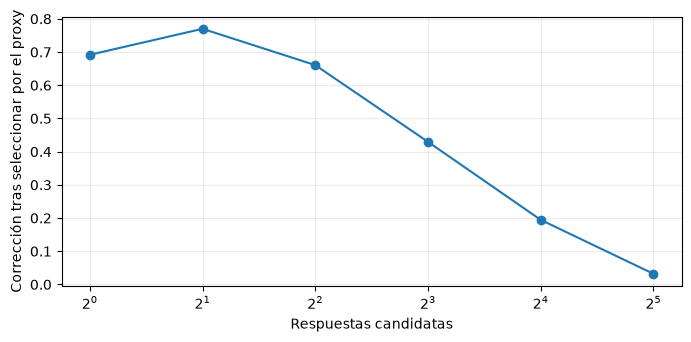

In [8]:
rng = np.random.default_rng(SEMILLA)
ns = [1, 2, 4, 8, 16, 32]
aciertos = []
for n in ns:
    candidatas = rng.choice(4, size=(6000, n), p=referencia)
    posiciones = proxy[candidatas].argmax(axis=1)
    elegidas = candidatas[np.arange(len(candidatas)), posiciones]
    aciertos.append(real[elegidas].mean())
plt.plot(ns, aciertos, "o-")
plt.xscale("log", base=2)
plt.xlabel("Respuestas candidatas")
plt.ylabel("Corrección tras seleccionar por el proxy")
plt.show()


En estas probabilidades, pasar de una a dos candidatas mejora inicialmente la corrección: también reduce la selección de respuestas irrelevantes. Al ampliar más la búsqueda, domina la respuesta incorrecta que maximiza el proxy. No debemos describir la curva como una caída monótona desde el primer punto.

Más cómputo optimiza más intensamente el criterio disponible. No corrige su especificación.

## 9. §§6.3–6.4 · Del ejemplo al agente real

En la dirección LLM para RL, un modelo puede interpretar observaciones, escribir recompensas, proponer acciones o generar código para simular el mundo. Un programa generado puede ejecutarse más barato que consultar un LLM en cada paso, pero hay que verificarlo. Latencia, longitud del contexto y memoria condicionan la arquitectura.

Con herramientas, una respuesta influye en futuras observaciones y recursos. Hay estados ocultos, acciones inválidas y crédito entre turnos. Varios módulos que cooperan con un objetivo común no constituyen automáticamente un juego competitivo como los del capítulo 5. La utilidad humana incierta tampoco queda resuelta por optimizar un proxy fijo.

El ejemplo del libro con Tinker y GEM organiza recogida de episodios, retornos, ventajas, pérdidas por token y actualización. Aquí no ejecutamos esos servicios. Sí podemos comprobar una regla básica: los tokens del entorno no son decisiones del agente y no deben recibir su pérdida de política.


In [9]:
log_prob_acciones = np.array([-0.8, -1.0, -0.2, -1.1, -0.7, -0.3])
es_agente = np.array([0, 1, 1, 0, 1, 0], dtype=bool)
# Valores centinela en posiciones del entorno: la máscara debe excluirlos.
ventajas = np.array([99, 1.2, 1.2, -99, -0.4, 99])
perdida = -(log_prob_acciones[es_agente]*ventajas[es_agente]).mean()
alteradas = log_prob_acciones.copy()
alteradas[~es_agente] -= 100  # Los tokens del entorno no deben cambiar la pérdida.
otra = -(alteradas[es_agente]*ventajas[es_agente]).mean()
assert perdida == otra
print("Pérdida enmascarada:", perdida, "Tokens del agente:", es_agente.sum())


Pérdida enmascarada: 0.38666666666666666 Tokens del agente: 3


Esta pérdida ilustrativa no contiene clipping ni KL: solo aísla la máscara. En una implementación real, además hay que alinear tokens, razones de probabilidad, final de episodios y normalizaciones.

## 10. Ejercicio: reparar la señal antes de optimizar más

Cambia la puntuación de la respuesta incorrecta convincente de 1.8 a 0.2. Predice primero cómo cambia el óptimo, y después entrena. Esta comparación distingue corregir el objetivo de frenar su optimización.


In [10]:
proxy_reparado = proxy.copy()
proxy_reparado[2] = 0.2
for nombre, recompensa in [("Original", proxy), ("Reparado", proxy_reparado)]:
    historia, p = entrenar(SEMILLA, recompensa, beta=0.1)
    print(nombre, "corrección aprendida:", p@real,
          "corrección óptima:", optimo(recompensa, 0.1)@real)


Original corrección aprendida: 0.030533395315245376 corrección óptima: 0.006591086807626679
Reparado corrección aprendida: 0.986626876499669 corrección óptima: 0.9999824176880552


<details>
<summary>Solución orientativa</summary>

Al reparar el proxy, una respuesta correcta pasa a ser la mejor puntuada. El aprendizaje ahora puede mejorar la corrección mientras aumenta su recompensa. La KL sigue regulando el desplazamiento, pero ya no está luchando contra una preferencia principal equivocada.

Si el verificador fallase solo en algunos prompts, este catálogo de un único contexto no detectaría ese problema. Hacen falta tareas variadas, evaluación independiente y análisis de los casos que el sistema aprende a explotar.

</details>

**Fuente:** adaptación de [Murphy, capítulo 6](https://arxiv.org/html/2412.05265v5#Ch6), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Código y respuestas sintéticas propios. [Resumen y experimento de referencia](../docs/06_llms.md).
